In [1]:
from collections import deque
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

working_directory = Path.cwd().resolve()
PROJECT_ROOT = (
    working_directory
    if (working_directory / "src" / "ncpu_computer_1d").is_dir()
    else working_directory.parent
)
SOURCE_ROOT = PROJECT_ROOT / "src"
if not (SOURCE_ROOT / "ncpu_computer_1d").is_dir():
    raise RuntimeError("Run this notebook from ncpu-em-1d or its notebooks folder")
sys.path.insert(0, str(SOURCE_ROOT))

import torch
from IPython.display import Image as DisplayImage, display

from ncpu_computer_1d import (
    ExperimentConfig, ModelConfig, MultiTaskDataset,
    NeuralCellularAutomaton, TapeLayout, TestCase, Trainer, TrainingConfig,
    binary_tasks, encode_strings, evaluate_cases, format_results, infer,
    load_model, round_half_up, save_gif, tape_bounds, task_target, validate_experiment, validate_task_specs,
)

# Tasks and type-independent direct tape interface
TASKS = (
    ("reverse", 3.0),
    ("copy", 1.0),
    ("shift_left_zero", 1.0),
    ("shift_right_zero", 1.0),
    ("gray_encode", 1.0),
    ("prefix_xor", 1.0),
    ("increment", 1.0),
)
TASK_NAMES, TASK_WEIGHTS = validate_task_specs(TASKS)
EXPERIMENT_NAME = "reverse_curriculum_1d_prefix4_mutable_p5_c5_6k"
# Task program and direct 1D local rule
PROGRAM_CHANNELS = 5
PROGRAM_MODE = "learned_read_only"  # zero, learned_read_only, learned_mutable
PROGRAM_LENGTH = 1
PROGRAM_PLACEMENT = "periodic"  # periodic or prefix; tape must contain all phases
PROGRAM_INIT_STD = 0.3
COMPUTATION_CHANNELS = 7
RADIUS = 1  # 1 or 2; one fixed bank, all kernels width 2*RADIUS+1
HIDDEN_SIZE = 128  # radius 2: use 64 to stay near 9k parameters
LEARNABLE_KERNELS = None  # None: 1 at radius 1, 2 at radius 2; integer overrides
LEARNABLE_KERNEL_INIT = "laplacian"
ACTIVATION = "relu"  # relu or softplus
GATE = "none"
GATE_BIAS = 1.0
FIRE_RATE = 0.95
STATE_LEAK = 0.01
MAX_ABS_STATE = 10.0

# One optimizer update accumulates one independently varied batch per base pair
# Every active task must leave at least one blank after both input and output
UPDATES = 7000
BATCH_SIZE_PER_TASK = 128
BASE_TAPE_SLOTS = (5, 8, 11, 15, 20)
BASE_INPUT_MAX_LENGTHS = (3, 5, 7, 10, 13)
TAPE_VARIATION = 0.20
INPUT_VARIATION = 0.20
FREE_STEPS_PER_TAPE_SLOT = 4.0
TIME_VARIATION = 0.20
SUPERVISION_RATIO = 1.5
LR_POINTS = (
    (0.00, 2e-3),
    (0.2, 1e-3),
    (0.6, 3e-4),
    (0.65, 5e-4),
    (0.75, 1.5e-4),
    (0.85, 8e-5),
    (1.0, 1e-5),
)
LR_INTERPOLATION = "cosine"  # cosine or linear
WEIGHT_DECAY = 1e-5
PROGRAM_WEIGHT_DECAY = 3e-5
GRAD_CLIP = 0.95
TRAIN_RULE = True
TRAIN_PROGRAM = True
PERCEPTION_NOISE_START = 0.0
PERCEPTION_NOISE_END = 0.0
SEED = 0
DEVICE = "auto"
VALIDATION_EVERY = 500
CHECKPOINT_EVERY = 500

# Fixed exact-length tests: +3/+5 beyond sampled training input ceiling 16
TEST_CASES = (
    TestCase("extrapolation_3_t4", 25, 19, 100, 150),
    TestCase("extrapolation_5_t4", 27, 21, 108, 162),
)
EVALUATION_BATCH_SIZE = 256
EVALUATION_MAX_EXAMPLES = 1000  # None evaluates every exact-length string

model_config = ModelConfig(
    program_channels=PROGRAM_CHANNELS,
    computation_channels=COMPUTATION_CHANNELS,
    program_mode=PROGRAM_MODE,
    program_length=PROGRAM_LENGTH,
    program_placement=PROGRAM_PLACEMENT,
    program_init_std=PROGRAM_INIT_STD,
    hidden_size=HIDDEN_SIZE,
    radius=RADIUS,
    learnable_kernels=LEARNABLE_KERNELS,
    learnable_kernel_init=LEARNABLE_KERNEL_INIT,
    activation=ACTIVATION,
    gate=GATE,
    gate_bias=GATE_BIAS,
    fire_rate=FIRE_RATE,
    state_leak=STATE_LEAK,
    max_abs_state=MAX_ABS_STATE,
    random_kernel_seed=SEED,
)
training_config = TrainingConfig(
    updates=UPDATES,
    batch_size_per_task=BATCH_SIZE_PER_TASK,
    base_tape_slots=BASE_TAPE_SLOTS,
    base_input_max_lengths=BASE_INPUT_MAX_LENGTHS,
    tape_variation=TAPE_VARIATION,
    input_variation=INPUT_VARIATION,
    free_steps_per_tape_slot=FREE_STEPS_PER_TAPE_SLOT,
    time_variation=TIME_VARIATION,
    supervision_ratio=SUPERVISION_RATIO,
    lr_points=LR_POINTS,
    lr_interpolation=LR_INTERPOLATION,
    weight_decay=WEIGHT_DECAY,
    program_weight_decay=PROGRAM_WEIGHT_DECAY,
    grad_clip=GRAD_CLIP,
    train_rule=TRAIN_RULE,
    train_program=TRAIN_PROGRAM,
    perception_noise_start=PERCEPTION_NOISE_START,
    perception_noise_end=PERCEPTION_NOISE_END,
    seed=SEED,
    validation_every=VALIDATION_EVERY,
    checkpoint_every=CHECKPOINT_EVERY,
    device=DEVICE,
)
config = ExperimentConfig(model_config, training_config, TEST_CASES)
checkpoint_dir = PROJECT_ROOT / "checkpoints" / (
    f"{EXPERIMENT_NAME}_{PROGRAM_MODE}_trials_{len(BASE_TAPE_SLOTS)}"
)
checkpoint_path = checkpoint_dir / "best.pt"

report = validate_experiment(config, TASK_NAMES)
print(report)
print(
    f"channels: program=0:{PROGRAM_CHANNELS}, shared I/O={model_config.io_channel}, "
    f"computation={model_config.io_channel + 1}:{model_config.channels}, "
    f"total={model_config.channels}"
)
print(f"program per task: ({PROGRAM_LENGTH}, {PROGRAM_CHANNELS}); {PROGRAM_PLACEMENT}; mode={PROGRAM_MODE}")
print("effective training tape ranges:", [tape_bounds(training_config, base, PROGRAM_LENGTH) for base in BASE_TAPE_SLOTS])
print(f"radius={RADIUS}; fixed kernels={model_config.fixed_kernels}; learned={model_config.learned_kernel_count}")
print(f"task weights: {dict(TASKS)}")
print(f"learning-rate schedule: {LR_INTERPOLATION} {LR_POINTS}")
for trial in sorted(report.sample_trials, key=lambda item: item.tape_slots):
    layout = TapeLayout(trial.tape_slots)
    print(
        f"\nSampled trial: tape={trial.tape_slots}, input<=L{trial.input_max_length}, "
        f"steps={trial.free_steps}+{trial.supervision_steps}\n{layout.schema()}"
    )
preview_tasks = binary_tasks(TASK_NAMES, min(2, max(BASE_INPUT_MAX_LENGTHS)))
preview = MultiTaskDataset.from_tasks(preview_tasks, max(3, PROGRAM_LENGTH, min(BASE_TAPE_SLOTS)))
print("\nOrdered examples (empty first; B is supervised blank padding):")
for index, source in enumerate(preview.datasets[0].input_strings):
    padded = (source + "B" * preview.tape_slots)[:preview.tape_slots]
    targets = {
        dataset.name: (dataset.target_strings[index] + "B" * preview.tape_slots)[:preview.tape_slots]
        for dataset in preview.datasets
    }
    print(padded, targets)


Validated: sampled trials, fixed exact-length test cases, direct ternary tape, program placement and masked leak, full-tape loss and program gradients
Parameters: 10,150
Tasks: reverse, copy, shift_left_zero, shift_right_zero, gray_encode, prefix_xor, increment
channels: program=0:5, shared I/O=5, computation=6:13, total=13
program per task: (1, 5); periodic; mode=learned_read_only
effective training tape ranges: [(4, 6), (6, 10), (9, 13), (12, 18), (16, 24)]
radius=1; fixed kernels=('identity', 'sobel_x', 'laplacian', 'neighbor_mean'); learned=1
task weights: {'reverse': 3.0, 'copy': 1.0, 'shift_left_zero': 1.0, 'shift_right_zero': 1.0, 'gray_encode': 1.0, 'prefix_xor': 1.0, 'increment': 1.0}
learning-rate schedule: cosine ((0.0, 0.002), (0.2, 0.001), (0.6, 0.0003), (0.65, 0.0005), (0.75, 0.00015), (0.85, 8e-05), (1.0, 1e-05))

Sampled trial: tape=5, input<=L3, steps=17+26
T T T T T
T: shared mutable I/O cell

Sampled trial: tape=7, input<=L5, steps=30+45
T T T T T T T
T: shared mutab

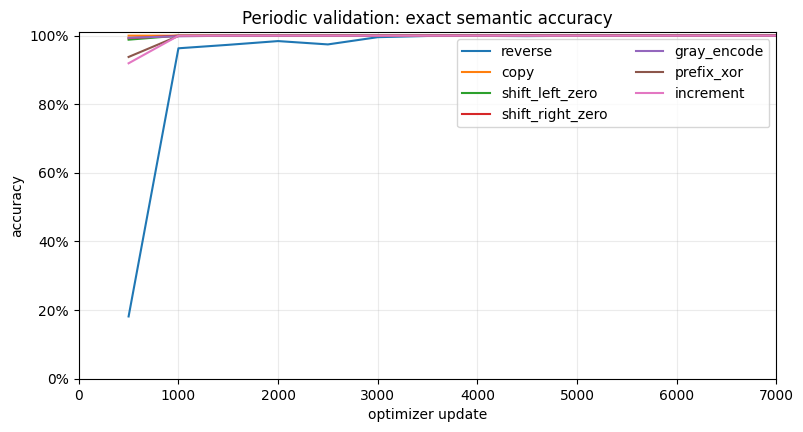

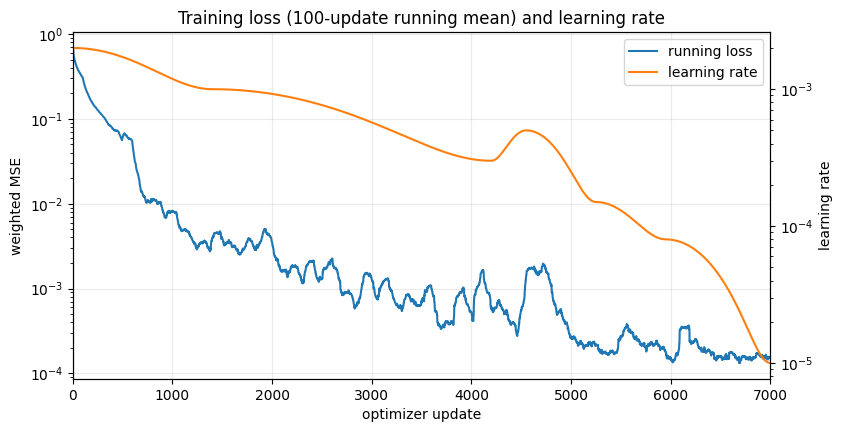

update    25/7000 loss=0.393601 semantic=19.71% raw=17.79% lr=0.002 noise=0
update    50/7000 loss=0.272209 semantic=38.86% raw=38.59% lr=0.002 noise=0
update    75/7000 loss=0.21257 semantic=59.64% raw=59.53% lr=0.00199 noise=0
update   100/7000 loss=0.179342 semantic=63.57% raw=63.44% lr=0.00199 noise=0
update   125/7000 loss=0.175852 semantic=77.23% raw=77.21% lr=0.00198 noise=0
update   150/7000 loss=0.156553 semantic=73.33% raw=73.17% lr=0.00197 noise=0
update   175/7000 loss=0.144656 semantic=80.49% raw=80.13% lr=0.00196 noise=0
update   200/7000 loss=0.113572 semantic=81.85% raw=81.83% lr=0.00195 noise=0
update   225/7000 loss=0.132793 semantic=80.16% raw=80.13% lr=0.00194 noise=0
update   250/7000 loss=0.12649 semantic=82.97% raw=82.92% lr=0.00192 noise=0
update   275/7000 loss=0.0970567 semantic=89.13% raw=89.08% lr=0.00191 noise=0
update   300/7000 loss=0.0851243 semantic=89.98% raw=89.98% lr=0.00189 noise=0
update   325/7000 loss=0.0820934 semantic=88.84% raw=88.84% lr=0.001

In [2]:
RUN_TRAINING = True
LOAD_CHECKPOINT = False
RESUME_LATEST = False
PROGRESS_EVERY = 25
LOSS_RUNNING_MEAN = 100


def training_plots(trainer):
    loss_window = deque(maxlen=LOSS_RUNNING_MEAN)
    training_updates, running_losses, learning_rates = [], [], []
    validation_updates = []
    validation_accuracies = {name: [] for name in TASK_NAMES}

    def record(update, loss, learning_rate, accuracies):
        loss_window.append(float(loss))
        training_updates.append(int(update))
        running_losses.append(max(sum(loss_window) / len(loss_window), 1e-12))
        learning_rates.append(float(learning_rate))
        if accuracies is not None:
            validation_updates.append(int(update))
            for name in TASK_NAMES:
                validation_accuracies[name].append(float(accuracies[name]))

    for entry in trainer.history:
        record(
            entry["update"], entry["loss"], entry["learning_rate"],
            entry.get("validation_accuracies"),
        )

    validation_figure, validation_axis = plt.subplots(figsize=(9, 4.5))
    validation_lines = {
        name: validation_axis.plot([], [], label=name)[0] for name in TASK_NAMES
    }
    validation_axis.set(
        title="Periodic validation: exact semantic accuracy",
        xlabel="optimizer update",
        ylabel="accuracy",
        xlim=(0, UPDATES),
        ylim=(0, 1.01),
    )
    validation_axis.yaxis.set_major_formatter(PercentFormatter(1.0))
    validation_axis.grid(alpha=0.25)
    validation_axis.legend(ncol=2)

    training_figure, loss_axis = plt.subplots(figsize=(9, 4.5))
    learning_rate_axis = loss_axis.twinx()
    loss_line = loss_axis.plot([], [], color="tab:blue", label="running loss")[0]
    learning_rate_line = learning_rate_axis.plot(
        [], [], color="tab:orange", label="learning rate"
    )[0]
    loss_axis.set(
        title=f"Training loss ({LOSS_RUNNING_MEAN}-update running mean) and learning rate",
        xlabel="optimizer update",
        ylabel="weighted MSE",
        xlim=(0, UPDATES),
    )
    learning_rate_axis.set_ylabel("learning rate")
    loss_axis.set_yscale("log")
    learning_rate_axis.set_yscale("log")
    loss_axis.set_ylim(1e-6, 1.0)
    schedule_rates = [rate for _, rate in LR_POINTS]
    learning_rate_axis.set_ylim(min(schedule_rates) / 2, max(schedule_rates) * 2)
    loss_axis.grid(alpha=0.25)
    loss_axis.legend(
        [loss_line, learning_rate_line],
        [loss_line.get_label(), learning_rate_line.get_label()],
    )

    validation_display = display(validation_figure, display_id=True)
    training_display = display(training_figure, display_id=True)
    plt.close(validation_figure)
    plt.close(training_figure)

    def update_plots(metrics):
        record(
            metrics.update, metrics.loss, metrics.learning_rate,
            metrics.validation_accuracies,
        )
        if metrics.validation_accuracies is not None:
            for name, line in validation_lines.items():
                line.set_data(validation_updates, validation_accuracies[name])
            validation_display.update(validation_figure)
        if metrics.update % PROGRESS_EVERY == 0 or metrics.validation_loss is not None:
            loss_line.set_data(training_updates, running_losses)
            learning_rate_line.set_data(training_updates, learning_rates)
            loss_axis.set_autoscaley_on(True)
            learning_rate_axis.set_autoscaley_on(True)
            loss_axis.relim()
            loss_axis.autoscale_view(scalex=False)
            learning_rate_axis.relim()
            learning_rate_axis.autoscale_view(scalex=False)
            training_display.update(training_figure)

    return update_plots


if RUN_TRAINING:
    latest = checkpoint_dir / "latest.pt"
    if RESUME_LATEST and latest.is_file():
        trainer = Trainer.from_checkpoint(latest, TASKS, device=DEVICE)
        if trainer.config != config:
            raise ValueError("checkpoint configuration differs from this notebook")
    else:
        trainer = Trainer(config, TASKS)
    plot_callback = training_plots(trainer)
    trainer.fit(
        checkpoint_dir, progress_every=PROGRESS_EVERY, callback=plot_callback
    )
    model = trainer.model
elif LOAD_CHECKPOINT:
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)
    model, loaded_config, checkpoint = load_model(checkpoint_path, DEVICE)
    stored_specs = tuple(tuple(spec) for spec in checkpoint["task_specs"])
    if loaded_config != config or stored_specs != TASKS:
        raise ValueError("checkpoint configuration or task weights differ")
else:
    device = torch.device(
        "cuda" if DEVICE == "auto" and torch.cuda.is_available()
        else "cpu" if DEVICE == "auto" else DEVICE
    )
    torch.manual_seed(SEED)
    model = NeuralCellularAutomaton(model_config, TASK_NAMES).to(device)

print(f"model device: {model.device}; parameters: {model.parameter_count:,}")


In [6]:
RUN_EVALUATION = True

if RUN_EVALUATION:
    evaluation_results = evaluate_cases(
        model,
        TASK_NAMES,
        TEST_CASES,
        batch_size=EVALUATION_BATCH_SIZE,
        seed=SEED,
        max_examples=EVALUATION_MAX_EXAMPLES,
    )
    print(format_results(evaluation_results))


case              task             n  tape   steps      mse    semantic      raw   symbol   stable
extrapolation_3_t reverse           1000    25  101-250  0.132376    51.43%   51.43%   95.94%   40.20%
extrapolation_3_t copy              1000    25  101-250  0.000024   100.00%  100.00%  100.00%  100.00%
extrapolation_3_t shift_left_zero   1000    25  101-250  0.000036   100.00%  100.00%  100.00%  100.00%
extrapolation_3_t shift_right_zero  1000    25  101-250  0.000031   100.00%  100.00%  100.00%  100.00%
extrapolation_3_t gray_encode       1000    25  101-250  0.000030   100.00%  100.00%  100.00%  100.00%
extrapolation_3_t prefix_xor        1000    25  101-250  0.003836    96.42%   96.42%   99.80%   95.80%
extrapolation_3_t increment         1000    25  101-250  0.000037   100.00%  100.00%  100.00%  100.00%
extrapolation_3_t aggregate         7000    25  101-250  0.019481    92.55%   92.55%   99.39%   90.86%
extrapolation_5_t reverse           1000    27  109-270  0.553334     3.92%  

InterpretedTape(raw='00111111BBB', binary_strings=('00111111',), integers=(), terminated=True, valid=True, integer_valid=False)


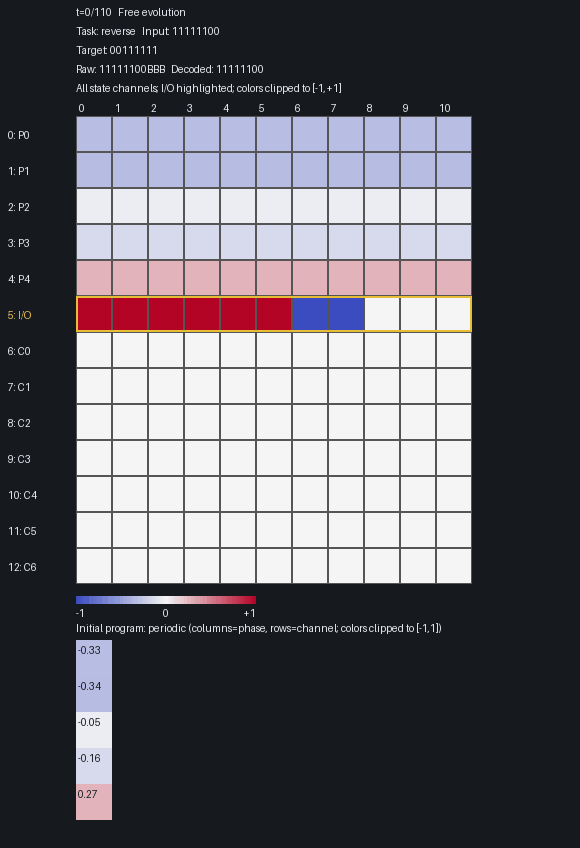

In [4]:
RUN_VISUALIZATION = True
VISUALIZATION_TASK = TASK_NAMES[0]
VISUALIZATION_INPUT = "11111100"
VISUALIZATION_TAPE_SLOTS = 11
VISUALIZATION_FREE_STEPS = round_half_up(FREE_STEPS_PER_TAPE_SLOT * VISUALIZATION_TAPE_SLOTS)
VISUALIZATION_SUPERVISION_STEPS = round_half_up(VISUALIZATION_FREE_STEPS * SUPERVISION_RATIO)
GIF_DURATION_MS = 80
GIF_SCALE = 36
GIF_PATH = PROJECT_ROOT / "outputs" / "output.gif"

if RUN_VISUALIZATION:
    if VISUALIZATION_TASK not in TASK_NAMES:
        raise ValueError("VISUALIZATION_TASK is not trained")
    if len(VISUALIZATION_INPUT) > VISUALIZATION_TAPE_SLOTS - 1:
        raise ValueError("visualized input must leave at least one blank tape slot")
    target_symbols = task_target(VISUALIZATION_TASK, VISUALIZATION_INPUT)
    if len(target_symbols) > VISUALIZATION_TAPE_SLOTS - 1:
        raise ValueError("visualized output must leave at least one blank")
    steps = VISUALIZATION_FREE_STEPS + VISUALIZATION_SUPERVISION_STEPS
    result = infer(
        model,
        VISUALIZATION_INPUT,
        tape_slots=VISUALIZATION_TAPE_SLOTS,
        task_name=VISUALIZATION_TASK,
        steps=steps,
        output_mode="single",
    )
    print(result.interpreted)
    layout = TapeLayout(VISUALIZATION_TAPE_SLOTS)
    encoded = encode_strings((VISUALIZATION_INPUT,), VISUALIZATION_TAPE_SLOTS).to(model.device)
    task_indices = torch.tensor([model.task_index(VISUALIZATION_TASK)], device=model.device)
    with torch.no_grad():
        trajectory = model(
            model.initial_state(encoded, task_indices), steps
        )[0]
    gif_path = save_gif(
        trajectory,
        GIF_PATH,
        layout=layout,
        config=config,
        program=model.programs[model.task_index(VISUALIZATION_TASK)],
        task_name=VISUALIZATION_TASK,
        input_symbols=VISUALIZATION_INPUT,
        target_symbols=target_symbols,
        free_steps=VISUALIZATION_FREE_STEPS,
        supervision_steps=VISUALIZATION_SUPERVISION_STEPS,
        output_mode="single",
        duration_ms=GIF_DURATION_MS,
        scale=GIF_SCALE,
    )
    display(DisplayImage(filename=str(gif_path)))


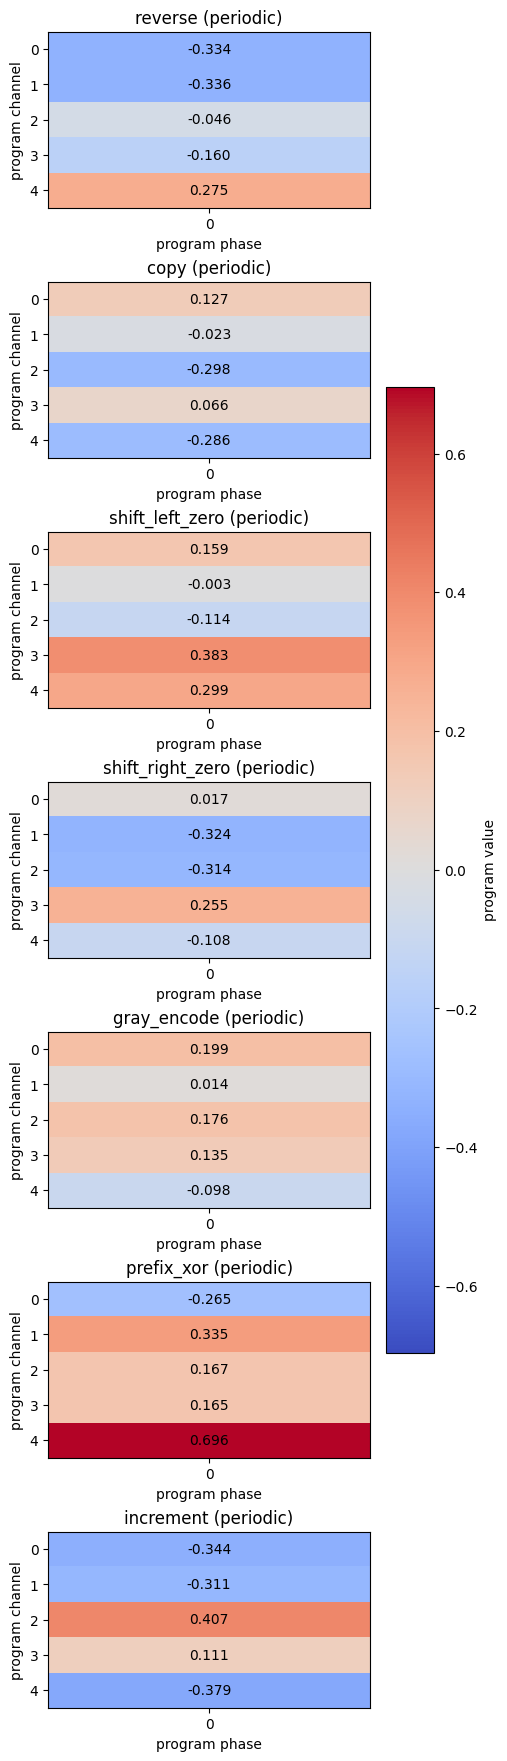

In [5]:
RUN_PROGRAM_PLOT = True

if RUN_PROGRAM_PLOT:
    programs = model.programs.detach().float().cpu()
    limit = max(float(programs.abs().max()), 1e-6)
    figure, axes = plt.subplots(
        len(model.task_names), 1, squeeze=False, constrained_layout=True,
        figsize=(max(5, model.config.program_length * 0.7), 2.5 * len(model.task_names)),
    )
    for task_index, axis in enumerate(axes[:, 0]):
        values = programs[task_index].T
        image = axis.imshow(values, cmap="coolwarm", vmin=-limit, vmax=limit, aspect="auto", interpolation="nearest")
        axis.set_xticks(range(model.config.program_length))
        axis.set_yticks(range(model.config.program_channels))
        axis.set(xlabel="program phase", ylabel="program channel", title=f"{model.task_names[task_index]} ({model.config.program_placement})")
        for channel in range(values.shape[0]):
            for phase in range(values.shape[1]):
                axis.text(phase, channel, f"{values[channel, phase]:.3f}", ha="center", va="center")
    figure.colorbar(image, ax=axes[:, 0].tolist(), shrink=0.7, label="program value")
    plt.show()
